# T-learner: cross-fitted CATE vs placebo

A T-learner fits two risk models with the same classifier (logistic regression):
one on the patients who received aspirin, one on those who did not. For each
patient, the CATE is the predicted risk under treatment minus the predicted risk
without it.

Each patient's CATE is predicted by a T-learner fitted on the other folds
(5-fold cross-fitting), so no patient is scored by a model that saw him.

As a reference, the same procedure is run with the treatment labels randomly
permuted across patients (placebo): any heterogeneity it finds is estimation
noise. The question is whether the true CATE shows more structure than the
placebo, judged on the uplift-by-decile curve. The test set is not used.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from ml_med.modeling import (
    cross_fit_cate,
    prepare_data,
    split_train_test,
    uplift_by_decile,
)

FEATURES_PATH = Path("../data/processed/ist_features.parquet")

In [2]:
df = pd.read_parquet(FEATURES_PATH)
X, y, t = prepare_data(df, "RXASP")
X_train, X_test, y_train, y_test, t_train, t_test = split_train_test(X, y, t)

In [3]:
cate = cross_fit_cate(X_train, y_train, t_train, "RXASP")
t_placebo = t_train.sample(frac=1, random_state=0).set_axis(t_train.index)
cate_placebo = cross_fit_cate(X_train, y_train, t_placebo, "RXASP")

pd.DataFrame({"true": cate.describe(), "placebo": cate_placebo.describe()})

,true,placebo
count,15428.000000,15428.000000
mean,-0.012450,-0.003013
std,0.050373,0.052126
min,-0.355624,-0.348391
25%,-0.041048,-0.028762
50%,-0.012567,-0.001366
75%,0.012810,0.024947
max,0.332048,0.483023


In [4]:
uplift_true = uplift_by_decile(cate, y_train, t_train).round(3)
uplift_placebo = uplift_by_decile(cate_placebo, y_train, t_placebo).round(3)
display(uplift_true)
display(uplift_placebo)

,n,cate_mean,rate_control,rate_treated,uplift
decile,,,,,
1,1543,-0.100,0.503,0.518,0.016
2,1543,-0.058,0.522,0.486,-0.037
3,1543,-0.041,0.516,0.485,-0.032
4,1542,-0.028,0.582,0.542,-0.040
5,1543,-0.018,0.664,0.651,-0.012
6,1543,-0.008,0.724,0.694,-0.031
7,1542,0.002,0.743,0.734,-0.009
8,1543,0.013,0.735,0.735,0.001
9,1543,0.030,0.705,0.700,-0.005


,n,cate_mean,rate_control,rate_treated,uplift
decile,,,,,
1,1543,-0.100,0.530,0.526,-0.004
2,1543,-0.049,0.597,0.570,-0.027
3,1543,-0.029,0.618,0.627,0.009
4,1542,-0.016,0.652,0.682,0.029
5,1543,-0.006,0.722,0.720,-0.002
6,1543,0.003,0.717,0.733,0.016
7,1542,0.012,0.699,0.688,-0.010
8,1543,0.025,0.617,0.635,0.018
9,1543,0.042,0.575,0.556,-0.019


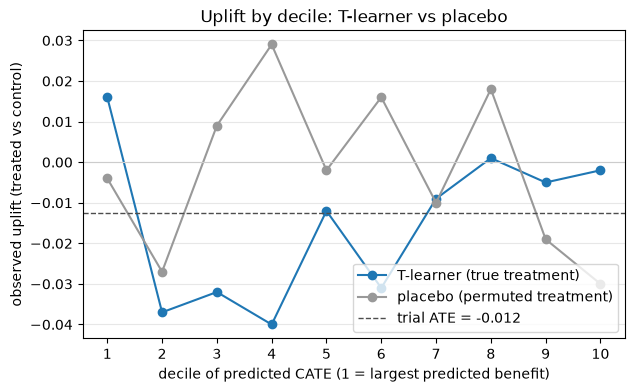

In [5]:
ate = y_train[t_train == 1].mean() - y_train[t_train == 0].mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    uplift_true.index,
    uplift_true["uplift"],
    marker="o",
    color="tab:blue",
    label="T-learner (true treatment)",
)
ax.plot(
    uplift_placebo.index,
    uplift_placebo["uplift"],
    marker="o",
    color="0.6",
    label="placebo (permuted treatment)",
)
ax.axhline(
    ate, linestyle="--", color="0.3", linewidth=1, label=f"trial ATE = {ate:.3f}"
)
ax.axhline(0, color="0.8", linewidth=0.8)
ax.set_xticks(uplift_true.index)
ax.set_xlabel("decile of predicted CATE (1 = largest predicted benefit)")
ax.set_ylabel("observed uplift (treated vs control)")
ax.set_title("Uplift by decile: T-learner vs placebo")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right")
plt.show()

## Conclusion

1. The T-learner recovers the average effect. The mean cross-fitted CATE is
−0.012, the same as the trial ATE (observed outcome rate in treated minus
controls). As an estimator of the average effect, the T-learner works.

2. The individual CATE is estimation noise. The spread of the predicted CATE
(std ≈ 0.05) is the same with the true treatment and with a permuted one, and
the uplift-by-decile curve is indistinguishable from the placebo curve: it
bounces around the ATE with the same amplitude, and decile 1, where the model
promises the largest benefit, shows no benefit at all. A single placebo is one
draw of noise; a bootstrap band (later) will make this comparison sharper.

3. The predicted CATE tracks baseline risk, not response. Control-arm outcome
rates are highest in the middle deciles. The difference of two logistic
predictions is mechanically largest where risk is near 0.5, so a T-learner on
the probability scale "finds" heterogeneity for a geometric reason, not a
clinical one.

This is the baseline. Any learner that claims heterogeneous effects must beat
this curve on the same metre: cross-fitted CATE, uplift by decile, placebo.

